# Exact and frozen-guide overlap distributions

**Kagome, L=2, N=12, periodic boundaries; eight disorders and 49 field contexts.**

We compare how much two independent 12-spin snapshots agree, first using the
exact ground state and then the frozen neural guide before GFMC projection.
The overlap $q$ measures that agreement; $P(q)$ gives the probability of each
possible overlap. The next section explains why there are only 13 such values,
spaced by 1/6, using a simple count of agreeing and disagreeing spins.
The first three figures compare exact and unprojected-guide distributions.
A separate guided-GFMC section below adds newly measured forward-walking histograms.

This notebook reads saved enumerated distributions and saved GFMC results; rerunning
its cells performs no new diagonalization or Monte Carlo simulation. The first three
figures show descriptive standard errors across eight disorders. The GFMC section
uses one disorder and separately labeled Monte Carlo errors. Lines connect discrete bins
as a visual aid. These small systems show finite-size crossovers; they do not
establish a thermodynamic phase boundary.

## Why there are only 13 overlap values

**There are 12 spins, and two spin configurations can disagree at 0, 1, 2, ...,
or 12 sites. That is 13 possible counts, including zero. Each count gives one
possible overlap value.**

A spin configuration is a snapshot of all 12 spins, each pointing up or down.
Take two independent snapshots for the same bonds and fields, and compare them
**at the same site**. Give a score of +1 when the spins agree (both up or both
down), and -1 when they disagree. The overlap, called $q$, is the average of
those 12 scores:

$$q=\frac{\text{number of agreeing sites}-\text{number of disagreeing sites}}{12}.$$

For example, if the snapshots agree at 10 sites and disagree at 2, the total
score is 10 minus 2 = 8. Dividing by 12 gives an overlap of **2/3**. It does not
matter which two sites disagree: every pair with two disagreements goes into
this same bin.

| Disagreeing sites | Agreeing sites | Overlap q |
|---:|---:|---:|
| 0 | 12 | 1 |
| 1 | 11 | 5/6 |
| 2 | 10 | 2/3 |
| 3 | 9 | 1/2 |
| 4 | 8 | 1/3 |
| 5 | 7 | 1/6 |
| 6 | 6 | 0 |
| 7 | 5 | -1/6 |
| 8 | 4 | -1/3 |
| 9 | 3 | -1/2 |
| 10 | 2 | -2/3 |
| 11 | 1 | -5/6 |
| 12 | 0 | -1 |

Each additional disagreement changes one score from +1 to -1, so the total
decreases by 2 and its average decreases by 2/12 = **1/6**. This explains the
spacing between the plotted points. An overlap of 0.1, for example, cannot
occur for an individual pair of these 12-spin snapshots.

**The 13 values are possible overlap results, not 13 spin configurations or
13 measurements.** There are 4,096 different spin snapshots and many more pairs,
but many pairs share the same number of disagreements. We collect their
probabilities into the same bin. The point's horizontal position is one of the
13 overlap values; its height is the probability of that value and need not be
a multiple of 1/6. Taking more measurements refines the heights without adding
new horizontal positions. Averaging probabilities over disorders also keeps
these same 13 positions.

More generally, a system with $N$ spins has **N + 1 possible overlap values**,
because the disagreement count runs from zero through N. Here $N=12$.

**Notation used later:** $q$ means the overlap score above; $P(q)$ means the
probability of that score. A subscript in $q_k$ just labels a bin, and a subscript
$J$ identifies the fixed set of bond couplings. Neither subscript is a sample
count. Only two snapshots enter each overlap. The GFMC calculation carries four
replicas to also measure connected observables, but uses the first two for this
histogram.

## What “Guide (unprojected)” means

**No GFMC propagation is used for the first three figures.** The later guided-GFMC
section is a separate, explicitly labeled calculation.
“Exact” uses the ground-state eigenvector $\psi_{0,J}$, whereas “Guide (unprojected)”
uses the frozen trained network $\psi_{G,J}$ directly:
$$p_{0,J}(s)=\frac{|\psi_{0,J}(s)|^2}{\sum_t|\psi_{0,J}(t)|^2},\qquad
  p_{G,J}(s)=\frac{|\psi_{G,J}(s)|^2}{\sum_t|\psi_{G,J}(t)|^2}.$$
The second plot compares the corresponding two-copy distributions computed from
these two choices of $p_J$. The network is evaluated with fixed parameters and the
specified bonds and fields; it is not retrained on these exact reference states.

“Unprojected” means no subsequent imaginary-time factor $e^{-\tau H_J}$ has been
applied to correct the trial state. The ongoing GFMC campaign is a separate
calculation. Its estimates do not enter the first three plots. There is therefore no walker
count, equilibration time, forward-walking time, or four-run Monte Carlo average
associated with these curves. They show the guide error that projection aims to correct.

## Computational details: from wavefunctions to P(q)

The Hamiltonian is
$$H_J=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-\Gamma\sum_iX_i-h\sum_iZ_i,
  \qquad K_{ij}\sim\mathcal U[0.5,1.5],\quad K=1.$$

| Item | Value / procedure |
|---|---|
| Geometry | Kagome $L=2$, $N=3L^2=12$, PBC in both directions |
| Basis | All $2^{12}=4096$ computational-basis configurations |
| Disorders | Eight fixed samples, IDs 50000–50007; the same bonds across fields and methods |
| Transverse fields | $\Gamma/K=0.25,0.5,0.75,1,1.5,2,3$ |
| Longitudinal fields | $h/K=0,0.05,0.10,0.15,0.20,0.25,0.30$ |
| Reference inputs | Stored normalized ground-state eigenvectors; full-space residual $\|H\psi-E\psi\|\leq10^{-9}$ |
| Reference solver | Sparse smallest-eigenvalue solver (`eigsh`, requested tolerance $10^{-12}$); compatible cached references reused |
| Zero-field reference | Spin-flip-even sector reconstructed in the full basis; odd-sector energy checked |
| Guide inputs | Stored float64 log amplitudes of the frozen seed501 symmetric transformer, evaluated on all 4096 states |
| Total | $8\times49=392$ contexts; 392 exact plus 392 guide distributions |

Frozen guide checkpoint SHA-256:
`5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`.

For each context and each choice of probability, the discrete probability mass is
$$P_J(q_k)=\sum_{s,t}p_J(s)p_J(t)\,\mathbf1[q(s,t)=q_k],\qquad
  \sum_kP_J(q_k)=1.$$
This is a deterministic sum over the full basis, **not a histogram of randomly
sampled configurations**. The guide probabilities are evaluated stably from
$\ell_s=\log\psi_G(s)$ as
$$p_G(s)=\frac{\exp[2(\ell_s-\max_t\ell_t)]}
                     {\sum_u\exp[2(\ell_u-\max_t\ell_t)]}.$$

The distribution-generation script avoids explicitly visiting all $4096^2$
configuration pairs by using XOR convolution. Encode configurations as bit strings,
let $x=s\oplus t$, and compute
$$c_J(x)=\sum_s p_J(s)p_J(s\oplus x)
   =2^{-N}\mathcal W\big[(\mathcal Wp_J)^2\big](x),$$
where $\mathcal W$ is the unnormalized Walsh–Hadamard transform, with
$\mathcal W^2=2^N I$. A bit set in $x$ marks a disagreeing spin. Sum $c_J(x)$ over
equal Hamming weights $d=\operatorname{popcount}(x)$ and assign the mass to
$q=1-2d/N$. The transform costs $O(N2^N)$ and uses $O(2^N)$ storage. The script
rejects negative convolution values below $-10^{-12}$, clips smaller roundoff
negatives to zero, and normalizes the resulting mass.

The saved distributions were checked for normalization, zero-field symmetry,
and agreement of their exact first, second, and fourth moments with independent
stored references. Input artifact hashes were recorded. This notebook reads the
resulting CSV, rechecks its probability structure, and computes the plots and
disorder summaries; it does not rerun the eigensolver or network.

## Disorder average and error bars

Compute each $P_J(q_k)$ using two copies of the **same disorder**, then average the
eight distributions with equal weights:
$$\overline P(q_k)=\frac1D\sum_{J=1}^{D}P_J(q_k),\qquad D=8.$$
We do not first average wavefunctions or pair configurations from different disorders.
In the second plot, every error bar is $\pm1$ standard error across disorders:
$$\mathrm{SE}[\overline P(q_k)]
  =\sqrt{\frac{1}{D(D-1)}\sum_J[P_J(q_k)-\overline P(q_k)]^2}.$$
These are pointwise descriptive bars, not simultaneous confidence bands; bins and
exact/guide values on the same disorder are correlated. They quantify disorder
variation, not eigensolver error, guide approximation error, or GFMC sampling error.
The vertical axis is probability **mass per allowed q value**, so masses sum to one
without multiplication by bin width. Connected line segments are only visual aids.

### What each plotted point represents

Each marker is the height of one discrete overlap bin: $P_J(q_k)$ is the
probability of observing $q_k$. For 12 spins there are **13 allowed overlaps**,
$q_k=-1+k/6$, $k=0,\ldots,12$. Lines join these heights only to guide the eye;
drawing bars would display the same probabilities. The heights sum to one.
A density-style histogram would instead have heights $P_J(q_k)/\Delta q$, with
$\Delta q=1/6$, so its area sums to one. This notebook plots probability mass.

### Disorder IDs, realizations and measurement counts

The label **sample 50000** is a disorder identifier. It means one fixed set of
random bonds, not 50,000 disorder realizations and not 50,000 measurements in each
histogram bin. Every bin and every method within a fixed-disorder panel uses
those same couplings. Across field panels the couplings remain fixed while
$\Gamma$ and $h$ change.

| Figure / curve | Disorder realizations | How the 13 bin heights are computed |
|---|---|---|
| Earlier exact / guide disorder averages | Eight, IDs 50000--50007 | Compute each complete distribution, then average the eight distributions equally |
| Exact / guide in the GFMC comparisons | One, ID 50000 | Deterministic probability sums over all basis-state pairs |
| Guided GFMC in the 4 × 4 and 7 × 7 comparisons | One, ID 50000 | Four independent runs on the same couplings; eight cycles and 512 walkers per run |

**Exact and unprojected guide.** For each disorder and field context, the 13 heights
are computed deterministically from all $2^{12}=4096$ basis configurations. The
pair formula contains $4096^2=16{,}777{,}216$ ordered configuration pairs, although
the implementation evaluates the equivalent XOR/Walsh convolution without looping
over every pair explicitly. Each bin receives the total probability mass of the
pairs having that overlap.

**Guided GFMC.** Each run has
$W=512$ walkers, and each walker carries four replicas. The histogram uses the
overlap of replicas 0 and 1, so one walker contributes one overlap tag per cycle.
There are eight forward-walking cycles, giving $512\times8=4096$ nominal tagged
walker contributions per run. Each plotted GFMC curve averages four independent
runs, giving
$$4\times512\times8=16{,}384$$
nominal contributions to the complete GFMC curve. These contributions are divided
among the 13 bins by their overlap values and are descendant-weighted after forward
propagation. The 16,384 count applies to the whole curve, not to each bin, and
does not mean 16,384 independent observations or distinct configuration pairs.
Walkers can share ancestors and the eight cycles are correlated. The four
replicas are not four independent disorder samples and do not multiply this
histogram count by four.

Let $n_{r,c,a}$ be the number of final descendants of tagged walker $a$ in cycle
$c$ of run $r$, and $q_{r,c,a}$ its overlap when tagged. Because the final population
has 512 walkers, $\sum_a n_{r,c,a}=512$. The displayed bin height is
$$\widehat P(q_k)=\frac{1}{4\times8\times512}
  \sum_{r=1}^{4}\sum_{c=1}^{8}\sum_{a=1}^{512}
  n_{r,c,a}\,\mathbf1[q_{r,c,a}=q_k].$$
An ancestor with no descendants contributes zero; one with several descendants
contributes several times. This is the mean of eight descendant-weighted cycle
histograms per run, followed by the mean of four run means. The error bars show one
Monte Carlo standard error across those **four run means**, not across 16,384
assumed-independent observations. The effective precision depends on ancestry,
time correlations and the bin being measured.

The ten energy-measurement blocks before the first tag and the propagation
intervals between tags do **not** provide extra histogram observations. Thus
neither those blocks nor the four replicas multiply the count above. Each curve
has 13 heights regardless of how many walkers, cycles or disorders are averaged.

Implementation sources:
[reference generation](../code/transformer_qmc/production_checks.py),
[overlap calculation](../code/transformer_qmc/assess_overlap_onset.py),
[GFMC histogram tags](../code/transformer_qmc/guided_overlap_demo.py),
[descendant-weighted estimator](../code/transformer_qmc/projector.py), and
[artifact provenance](../data/kagome/transformer_af_production_v1/overlap_onset/provenance.json).

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/kagome/transformer_af_production_v1/overlap_onset').is_dir())
DATA = ROOT / 'data/kagome/transformer_af_production_v1/overlap_onset'
OUT = ROOT / 'figures/exact_guide_overlap'
OUT.mkdir(parents=True, exist_ok=True)
source = DATA / 'exact_and_guide_pq_by_disorder.csv'
raw = pd.read_csv(source)
keys = ['method', 'gamma', 'h', 'sample_id']
assert not raw.duplicated(keys + ['q']).any()
assert set(raw.method) == {'exact', 'guide'}
assert (raw.N == 12).all() and (raw.L == 2).all()
assert np.isfinite(raw[['q', 'probability']].to_numpy()).all()
assert (raw.probability >= 0).all()
np.testing.assert_allclose(raw.groupby(keys).probability.sum(), 1, atol=1e-12)
assert (raw.groupby(keys).size() == 13).all()
assert (raw.groupby(['method', 'gamma', 'h']).sample_id.nunique() == 8).all()
gammas = sorted(raw.gamma.unique())
fields = sorted(raw.h.unique())
assert len(gammas) == len(fields) == 7
q = np.sort(raw.q.unique())
np.testing.assert_allclose(q, np.linspace(-1, 1, 13), atol=1e-12)
for _, group in raw[raw.h == 0].groupby(keys):
    mass = group.sort_values('q').probability.to_numpy()
    np.testing.assert_allclose(mass, mass[::-1], atol=1e-10)
summary = raw.groupby(['method', 'gamma', 'h', 'q']).probability.agg(
    mean='mean', std='std', count='count').reset_index()
summary['se'] = summary['std'] / np.sqrt(summary['count'])
print(f'Validated {raw.groupby(keys).ngroups} distributions; '
      f'{raw.sample_id.nunique()} disorders, {len(gammas)*len(fields)} contexts per method.')
print('Input SHA-256:', hashlib.sha256(source.read_bytes()).hexdigest())
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})

def distribution(method, gamma, h):
    return summary[(summary.method == method) & np.isclose(summary.gamma, gamma)
                   & np.isclose(summary.h, h)].sort_values('q')

def save_figure(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight')

Validated 784 distributions; 8 disorders, 49 contexts per method.
Input SHA-256: d94a41b5639bb65a6f8610e33e3873267c99aa3d01d9e83da74b8afde9c1b0cf


## Field overview

Both rows use the same color scale. Gamma rows are categorical and equally spaced
visually; use the tick labels for their numerical values. Change `shown_fields`
below to inspect other saved fields.

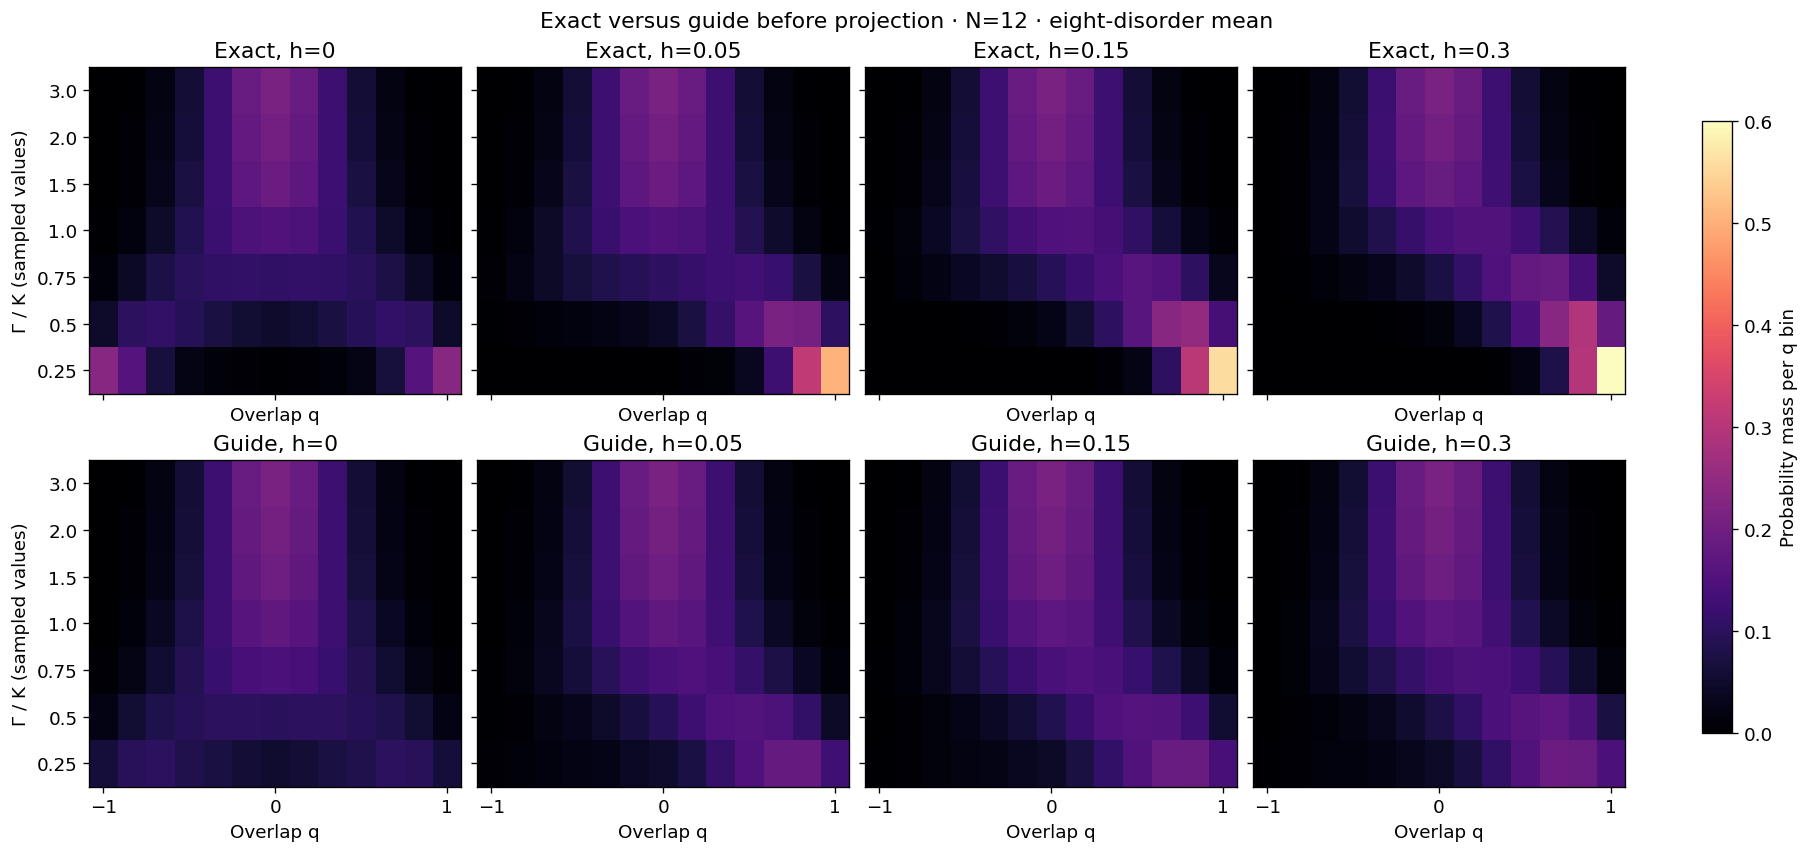

In [2]:
shown_fields = [0., .05, .15, .30]
fig, axes = plt.subplots(2, len(shown_fields), figsize=(15, 7),
                         sharex=True, sharey=True, layout='constrained', squeeze=False)
vmax = summary['mean'].max()
for row, method in enumerate(['exact', 'guide']):
    for col, h in enumerate(shown_fields):
        mass = np.array([distribution(method, g, h)['mean'] for g in gammas])
        im = axes[row, col].imshow(mass, origin='lower', aspect='auto',
                                   cmap='magma', vmin=0, vmax=vmax,
                                   interpolation='nearest')
        axes[row, col].set(xticks=[0, 6, 12], xticklabels=['−1', '0', '1'],
                           yticks=range(len(gammas)), yticklabels=gammas,
                           xlabel='Overlap q', title=f'{method.capitalize()}, h={h:g}')
        if col == 0:
            axes[row, col].set_ylabel('Γ / K (sampled values)')
fig.colorbar(im, ax=axes, label='Probability mass per q bin', shrink=.85)
fig.suptitle('Exact versus guide before projection · N=12 · eight-disorder mean')
save_figure(fig, 'heatmap')
plt.show()

## Direct comparisons with disorder uncertainty

The selected transverse fields span the strong mismatch at low Gamma and the
close agreement at Gamma=2. Each error bar is ±1 disorder SE. Exact and guide
use the same disorders, so their errors are paired; overlapping error bars are
not a formal test of their difference. Edit `selected_gammas` and
`selected_fields` to choose other contexts from the saved grid.

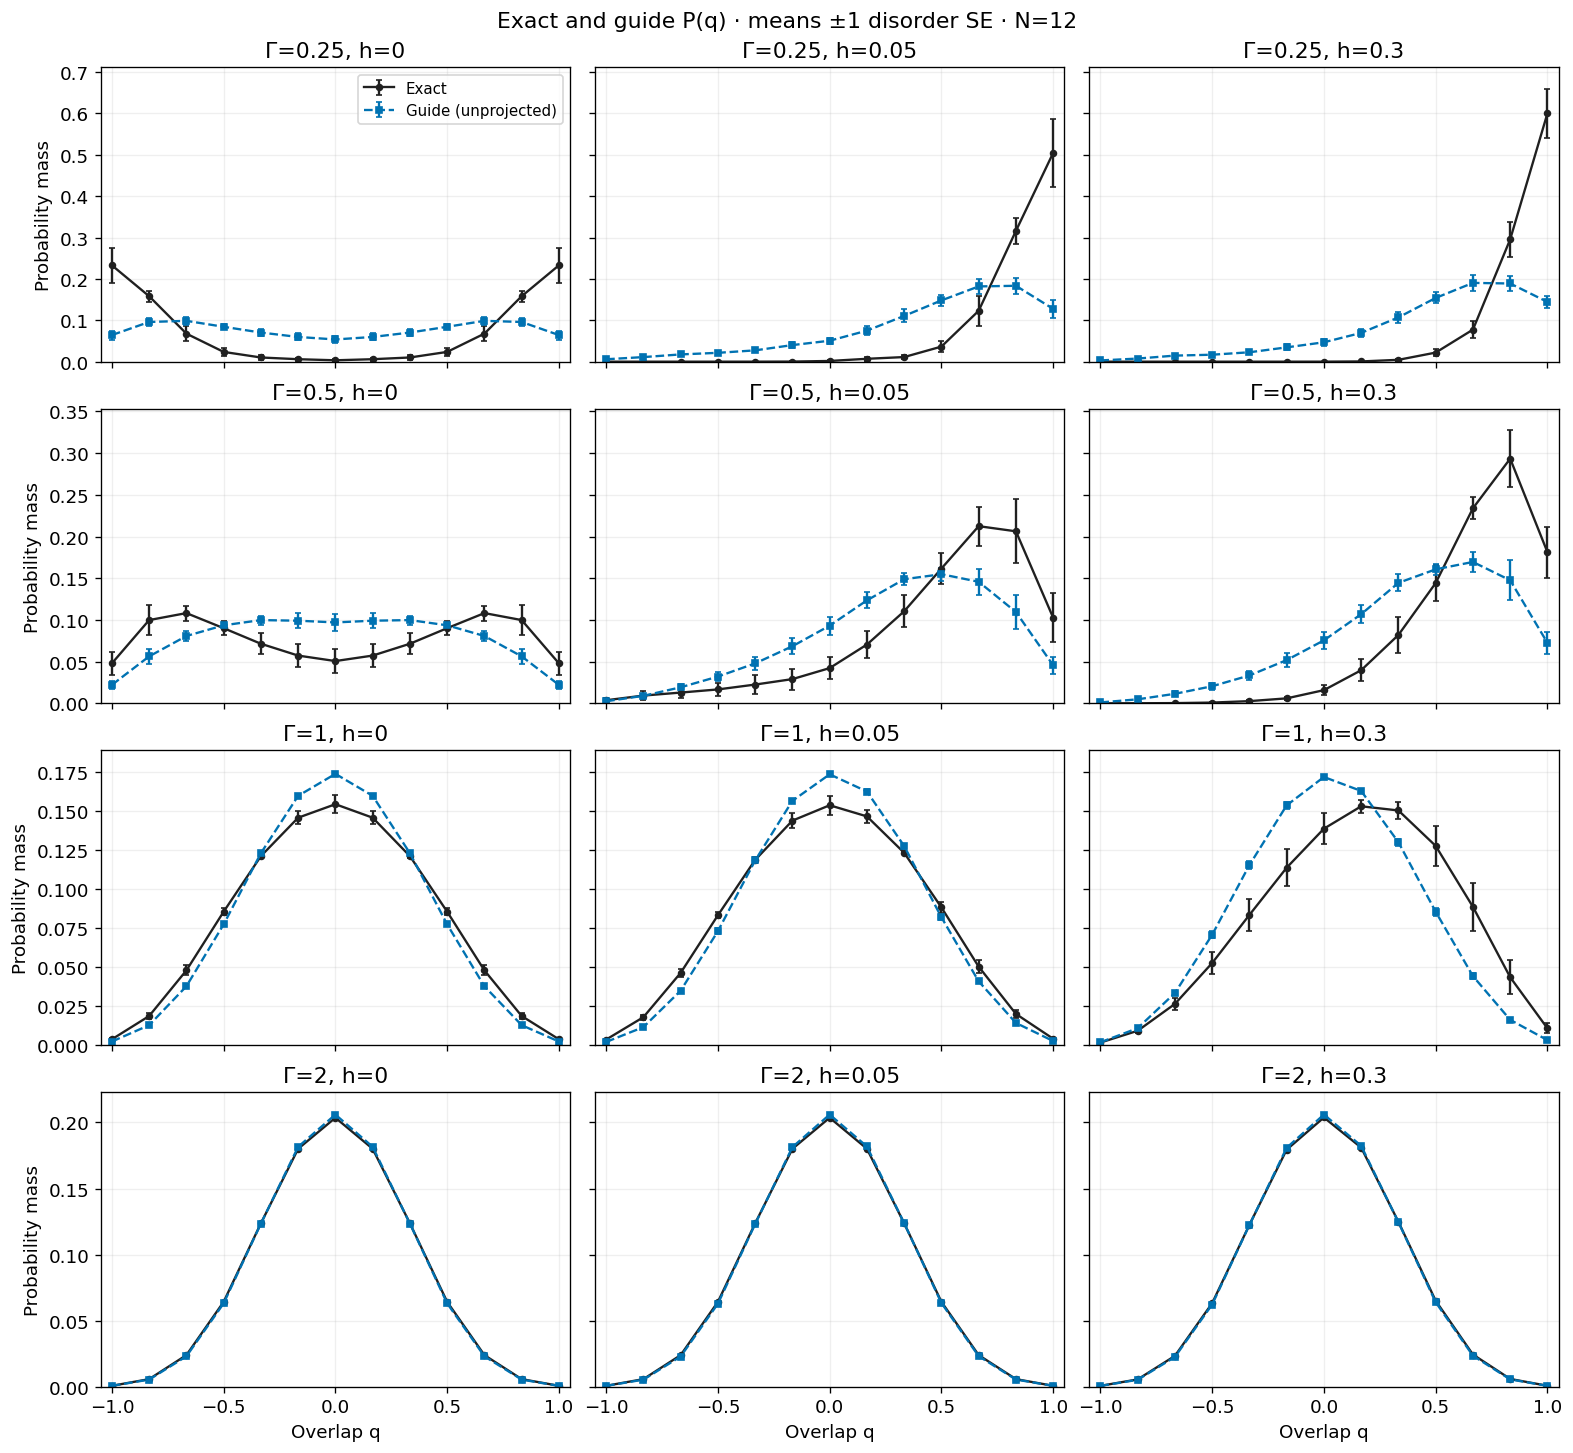

In [3]:
selected_gammas = [.25, .5, 1., 2.]
selected_fields = [0., .05, .30]
fig, axes = plt.subplots(len(selected_gammas), len(selected_fields),
                         figsize=(13, 12), sharex=True, sharey='row',
                         layout='constrained', squeeze=False)
for i, gamma in enumerate(selected_gammas):
    for j, h in enumerate(selected_fields):
        ax = axes[i, j]
        for method, color, marker in [('exact', '#202020', 'o'),
                                       ('guide', '#0072B2', 's')]:
            d = distribution(method, gamma, h)
            ax.errorbar(d.q, d['mean'], yerr=d.se, color=color, marker=marker,
                        markersize=3.5, linewidth=1.4, capsize=2,
                        linestyle='-' if method == 'exact' else '--',
                        label='Exact' if method == 'exact' else 'Guide (unprojected)')
        ax.set(title=f'Γ={gamma:g}, h={h:g}', xlim=(-1.05, 1.05),
               xticks=[-1, -.5, 0, .5, 1])
        ax.grid(alpha=.2)
        if i == len(selected_gammas)-1:
            ax.set_xlabel('Overlap q')
        if j == 0:
            ax.set_ylabel('Probability mass')
for i, gamma in enumerate(selected_gammas):
    upper = max((distribution(method, gamma, h)['mean']
                 + distribution(method, gamma, h)['se']).max()
                for method in ['exact', 'guide'] for h in selected_fields)
    axes[i, 0].set_ylim(0, 1.08 * upper)
axes[0, 0].legend(fontsize=9)
fig.suptitle('Exact and guide P(q) · means ±1 disorder SE · N=12')
save_figure(fig, 'distribution_curves')
plt.show()

## How much does the guide differ?

Compute total variation **within each disorder**, then average:
$$\mathrm{TV}_J=\tfrac12\sum_q |P_{J,\mathrm{exact}}(q)-P_{J,\mathrm{guide}}(q)|.$$
TV=0 means identical distributions; TV=1 means disjoint support. Taking the
difference after disorder averaging could hide sample-specific discrepancies.

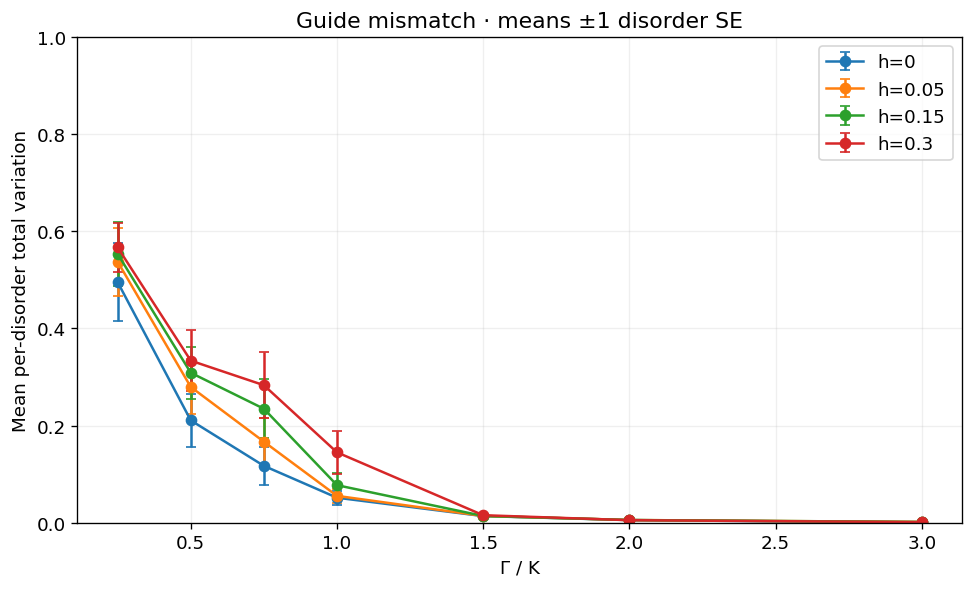

h,0.00,0.05,0.10,0.15,0.20,0.25,0.30
gamma,,,,,,,
0.25,0.4951,0.5373,0.5494,0.5533,0.5599,0.5664,0.5667
0.50,0.2106,0.2794,0.2905,0.3086,0.3217,0.3295,0.3336
0.75,0.1170,0.1667,0.2052,0.2345,0.2538,0.2686,0.2830
1.00,0.0514,0.0552,0.0616,0.0772,0.0988,0.1218,0.1448
1.50,0.0135,0.0138,0.0137,0.0138,0.0140,0.0145,0.0154
2.00,0.0054,0.0055,0.0055,0.0054,0.0053,0.0052,0.0051
3.00,0.0005,0.0014,0.0015,0.0015,0.0015,0.0013,0.0011


Figures and tables saved to figures/exact_guide_overlap


In [4]:
paired = raw.pivot(index=['sample_id', 'gamma', 'h', 'q'],
                   columns='method', values='probability')
assert not paired.isna().any().any()
tv = (.5 * (paired.exact - paired.guide).abs()).groupby(
    level=['sample_id', 'gamma', 'h']).sum().rename('tv').reset_index()
tv_summary = tv.groupby(['gamma', 'h']).tv.agg(mean='mean', std='std', count='count').reset_index()
tv_summary['se'] = tv_summary['std'] / np.sqrt(tv_summary['count'])
fig, ax = plt.subplots(figsize=(8, 4.8), layout='constrained')
for h in shown_fields:
    d = tv_summary[np.isclose(tv_summary.h, h)].sort_values('gamma')
    ax.errorbar(d.gamma, d['mean'], yerr=d.se, marker='o', capsize=3, label=f'h={h:g}')
ax.set(xlabel='Γ / K', ylabel='Mean per-disorder total variation', ylim=(0, 1),
       title='Guide mismatch · means ±1 disorder SE')
ax.grid(alpha=.2)
ax.legend()
save_figure(fig, 'guide_mismatch')
plt.show()
display(tv_summary.pivot(index='gamma', columns='h', values='mean').round(4))
summary.to_csv(OUT / 'distribution_summary.csv', index=False)
tv_summary.to_csv(OUT / 'mismatch_summary.csv', index=False)
print('Figures and tables saved to', OUT.relative_to(ROOT))

## Interpretation of the unprojected-guide comparison

- At large Gamma, both distributions concentrate near zero overlap and agree closely.
- At low Gamma and h=0, exact probability shifts toward both overlap extremes.
  Symmetry keeps the mean overlap zero even when the second moment is large.
- Nonzero h favors positive overlap. In the low-Gamma cases the guide substantially
  underestimates the exact concentration at large positive overlap.
- This measures error in the unprojected guide. GFMC is intended to correct it;
  its overlap distribution requires separately recorded forward-walking histograms.

Source details: [research note](../data/kagome/transformer_af_production_v1/overlap_onset/RESEARCH_NOTE.md).

## Guided GFMC: a measured 12-spin demonstration

**The green curves below are new stochastic guided-GFMC measurements.** They use
the same frozen network as above, represented by its stored float64 log amplitudes
on all 4096 states. Table lookup replaces repeated network inference; the exact
eigenvector is used only as a reference, never as the guide or initialization.
These small-system timings do not predict the cost of direct neural inference at L=4.

This section uses **one fixed disorder, ID 50000**, chosen as the first benchmark
sample before running the demonstration. All plotted references use that same
disorder. They are not the eight-disorder means shown earlier.

| Setting | Value |
|---|---|
| Contexts | $\Gamma=0.5,2$ and $h=0,0.05$ |
| Independent runs | Four per context; 16 runs total, fixed independent seeds |
| Population | $W=512$ walkers, each carrying four physical replicas |
| Initialization | Independent configurations from normalized $|\psi_G|^2$ |
| Equilibration | $\tau_{\rm eq}=4$ |
| Energy measurement before first tag | Time 1 |
| Forward projection | $\tau_{\rm FW}=2$ per cycle |
| Cycles | Eight; tag times $t_c=5+2c$, $c=0,\ldots,7$ |
| Branch interval | 0.1; continuous-time spin flips within each interval |
| Precision / execution | Float64 arithmetic, local CPU lookup guide |

At each tag time, attach a one-hot vector to each walker:
$b_{a,k}=\mathbf1[q(s_a^{(0)},s_a^{(1)})=q_k]$. Propagate for time 2, retaining
the ancestor index of each descendant. With $n_a$ descendants of ancestor $a$,
$$\widehat P_{r,c}(q_k)=\frac1W\sum_a n_a b_{a,k},\qquad \sum_a n_a=W.$$
All four replicas branch jointly. The histogram uses replicas 0 and 1, matching
the existing scalar overlap estimator. Average the eight cycle histograms within
each run and then the four independent run means with equal weights. Cycles are
correlated and are not used as independent observations for error bars. The green
error bars show $\pm\operatorname{sd}_r(\widehat P_r)/\sqrt4$ (one Monte Carlo SE),
not disorder uncertainty or a confidence bound on projection bias. All cycles are retained.

### Finite-time benchmark and validation

Finite projection can differ from the ground state even at infinite population.
To separate this from sampling/population effects, the orange curve is computed
deterministically at exactly the same tag and forward times. Write
$$\phi_t=e^{-t(H-E_0)}\psi_G,\qquad
  p_c(s)=\frac{\phi_{t_c}(s)\phi_{\tau_{\rm FW}}(s)}
               {\sum_u\phi_{t_c}(u)\phi_{\tau_{\rm FW}}(u)}.$$
The infinite-population descendant-weighted distribution is obtained by applying
the same two-copy XOR convolution to $p_c$, then averaging the eight cycle
distributions. It is the average of distributions, not the distribution of an
averaged $p_c$. The energy shift $E_0$ stabilizes the matrix exponential and cancels
in normalization. This reference has no population or resampling error.

Histogram normalization and its first, second, and fourth moments are checked
against the scalar estimator **in every measured cycle**. Separate regression
checks compare ancestry weighting to scalar moments and compare the finite-time
reference to dense matrix exponentiation and explicit pair enumeration on three
spins, including a stationary exact-ground-state check.

This is a demonstration, **not ground-state qualification**: it has one disorder
and one population/time setting, with no convergence ladder. Its outputs and
source snapshot are separate from the active 48-spin production campaign.

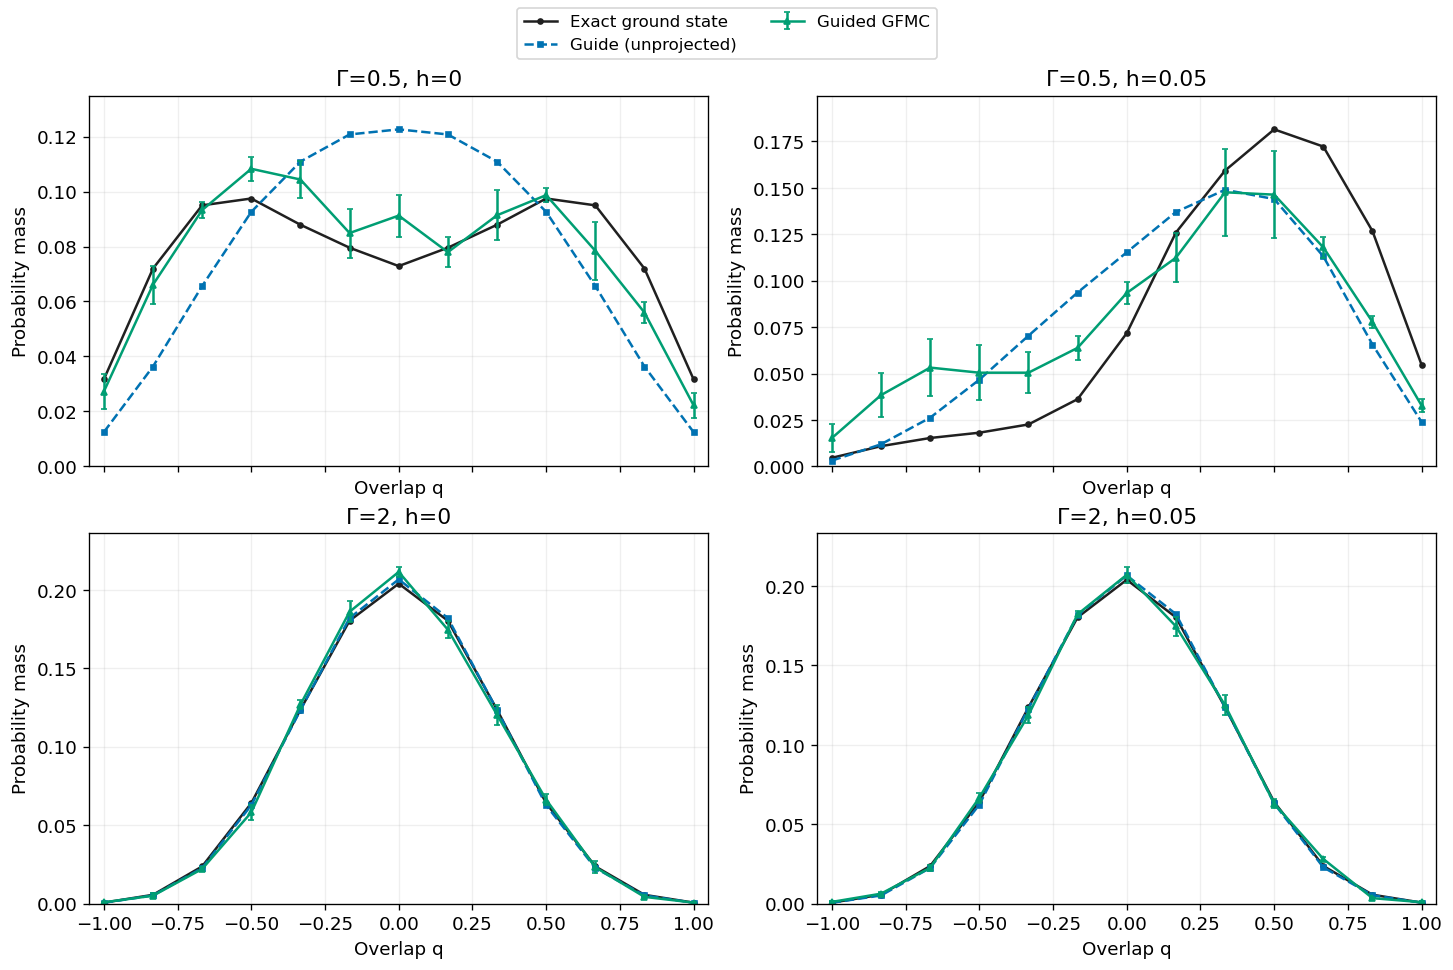

,gamma,h,guide_TV_to_ground,finite_time_TV_to_ground,GFMC_TV_to_ground,GFMC_TV_to_finite_time,minimum_ESS,maximum_lineage,ancestry_alarms,CPU_run_seconds
0,0.5,0.00,0.17810,0.07029,0.05564,0.04058,49.98932,0.08398,0,1.92889
1,0.5,0.05,0.20036,0.16032,0.18548,0.03962,13.44053,0.25781,0,1.92064
2,2.0,0.00,0.00611,0.00000,0.01884,0.01884,194.18074,0.01758,0,7.18538
3,2.0,0.05,0.00632,0.00000,0.01487,0.01487,171.33595,0.02148,0,7.46778


Validated 16 runs × 8 cycles; all histogram moments match the scalar tags.
Total GFMC propagation wall time (local CPU, excluding reference computation): 18.5 seconds


In [12]:
import json
DEMO = ROOT / 'data/kagome/guided_overlap_demo_v1'
demo_manifest = json.loads((DEMO / 'manifest.json').read_text())
for relative, digest in demo_manifest['source_sha256'].items():
    assert hashlib.sha256((DEMO / 'source' / relative).read_bytes()).hexdigest() == digest
demo_rows = []
demo_tables = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, layout='constrained')
for ax, (gamma, h) in zip(axes.flat, demo_manifest['contexts']):
    stem = f'L2_s50000_g{gamma:g}_h{h:g}_K1'.replace('.', 'p')
    ref = json.loads((DEMO / (stem + '_reference.json')).read_text())
    for relative, digest in ref['input_sha256'].items():
        assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == digest
    runs = [json.loads((DEMO / (stem + f'_repeat{r}.json')).read_text()) for r in range(4)]
    assert len({r['seed'] for r in runs}) == 4
    q_demo = np.asarray(ref['q'])
    for run in runs:
        assert run['parameters'] == demo_manifest['parameters']
        assert run['input_sha256'] == ref['input_sha256']
        hist = np.asarray(run['result']['pq_cycles'])
        np.testing.assert_allclose(hist.sum(1), 1, atol=1e-12)
        for power, name in [(1, 'q'), (2, 'q2'), (4, 'q4')]:
            np.testing.assert_allclose(hist @ q_demo**power, run['result'][name + '_cycles'], atol=1e-12)
        np.testing.assert_allclose(hist.mean(0), run['result']['pq'], atol=1e-12)
    estimates = np.array([r['result']['pq'] for r in runs])
    mean, se = estimates.mean(0), estimates.std(0, ddof=1) / 2
    ax.plot(q_demo, ref['exact'], 'o-', color='#202020', markersize=3, label='Exact ground state')
    ax.plot(q_demo, ref['guide'], 's--', color='#0072B2', markersize=3, label='Guide (unprojected)')
    # ax.plot(q_demo, ref['finite_time'], ':', color='#D55E00', linewidth=2.5,
    #         label='Infinite-population finite-time reference')
    # ax.errorbar(q_demo, mean, yerr=se, fmt='^-', color='#009E73', markersize=4,
    #             capsize=2, label='Guided GFMC ±1 run SE')
    ax.errorbar(q_demo, mean, yerr=se, fmt='^-', color='#009E73', markersize=4,
                capsize=2, label='Guided GFMC')
    upper = max(max(ref['exact']), max(ref['guide']), max(ref['finite_time']), max(mean + se))
    ax.set(title=f'Γ={gamma:g}, h={h:g}', xlabel='Overlap q', ylabel='Probability mass',
           xlim=(-1.05, 1.05), ylim=(0, 1.1 * upper))
    ax.grid(alpha=.2)
    demo_rows.append(dict(gamma=gamma, h=h,
        guide_TV_to_ground=.5*np.abs(np.asarray(ref['guide'])-ref['exact']).sum(),
        finite_time_TV_to_ground=.5*np.abs(np.asarray(ref['finite_time'])-ref['exact']).sum(),
        GFMC_TV_to_ground=.5*np.abs(mean-ref['exact']).sum(),
        GFMC_TV_to_finite_time=.5*np.abs(mean-ref['finite_time']).sum(),
        minimum_ESS=min(min(r['result']['descendant_ess']) for r in runs),
        maximum_lineage=max(max(r['result']['largest_lineage']) for r in runs),
        ancestry_alarms=sum(r['ancestry_alarm'] for r in runs),
        CPU_run_seconds=sum(r['seconds'] for r in runs)))
    for k, value in enumerate(q_demo):
        demo_tables.append(dict(gamma=gamma, h=h, q=value, exact=ref['exact'][k],
            guide=ref['guide'][k], finite_time=ref['finite_time'][k], GFMC_mean=mean[k], GFMC_se=se[k]))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=2, fontsize=10)
save_figure(fig, 'guided_gfmc_demo')
plt.show()
diagnostics = pd.DataFrame(demo_rows)
display(diagnostics.round(5))
pd.DataFrame(demo_tables).to_csv(OUT / 'guided_gfmc_demo_histograms.csv', index=False)
diagnostics.to_csv(OUT / 'guided_gfmc_demo_diagnostics.csv', index=False)
print('Validated 16 runs × 8 cycles; all histogram moments match the scalar tags.')
print('Total GFMC propagation wall time (local CPU, excluding reference computation):',
      round(diagnostics.CPU_run_seconds.sum(), 2), 'seconds')

Read the green-versus-orange discrepancy as sampling and finite-population effects;
read the orange-versus-black discrepancy as finite-projection bias at these times.
Total variation computed from the noisy GFMC mean is a descriptive plug-in distance,
not an unbiased error estimate or an acceptance test. Four repeats give uncertain
variance estimates. An ancestry alarm is any cycle with ESS<8 or largest lineage>0.5;
absence of alarms does not establish convergence.

**Observed in this demonstration:** at Gamma=2 the deterministic finite-time
reference is almost indistinguishable from the ground-state distribution (TV below
0.000004 for both fields). The stochastic histogram still has finite-run noise.
At Gamma=0.5, deterministic residual TV is about 0.070 at h=0 and 0.160 at h=0.05.
Thus these projection times remain insufficient at low Gamma, even at infinite
population. All 16 runs clear the ancestry alarm, illustrating that ancestry
health alone does not certify physical convergence. At h=0 the exact and
deterministic curves are symmetric; the measured GFMC histogram is shown without
symmetrization, retaining its sampling asymmetry.

The original demonstration source is preserved under
`data/kagome/guided_overlap_demo_v1/source/code/transformer_qmc/guided_overlap_demo.py`.
Run the preserved source with its preserved dependencies to reproduce its version;
later grid extensions have a separate manifest and source snapshot.
Completed runs are reused with frozen inputs and source identities. The local
demonstration uses the stored 12-spin guide table and does not require a GPU.

## Selected 4 × 4 comparison: exact, guide and guided GFMC

This compact figure shows only the exact ground state, the unprojected guide,
and measured guided GFMC. Rows use $\Gamma=0.25,0.5,1,2$ and columns use
$h=0,0.05,0.15,0.30$. All curves use the same fixed disorder 50000, with the GFMC
settings documented above. Error bars are ±1 Monte Carlo SE across four independent
runs. Each panel has its own vertical scale; the top-left panel extends to 0.3.
These are finite-time measurements, not
convergence-qualified ground-state distributions. The full 7 × 7 comparison,
including the finite-time reference, is retained at the end of the notebook.

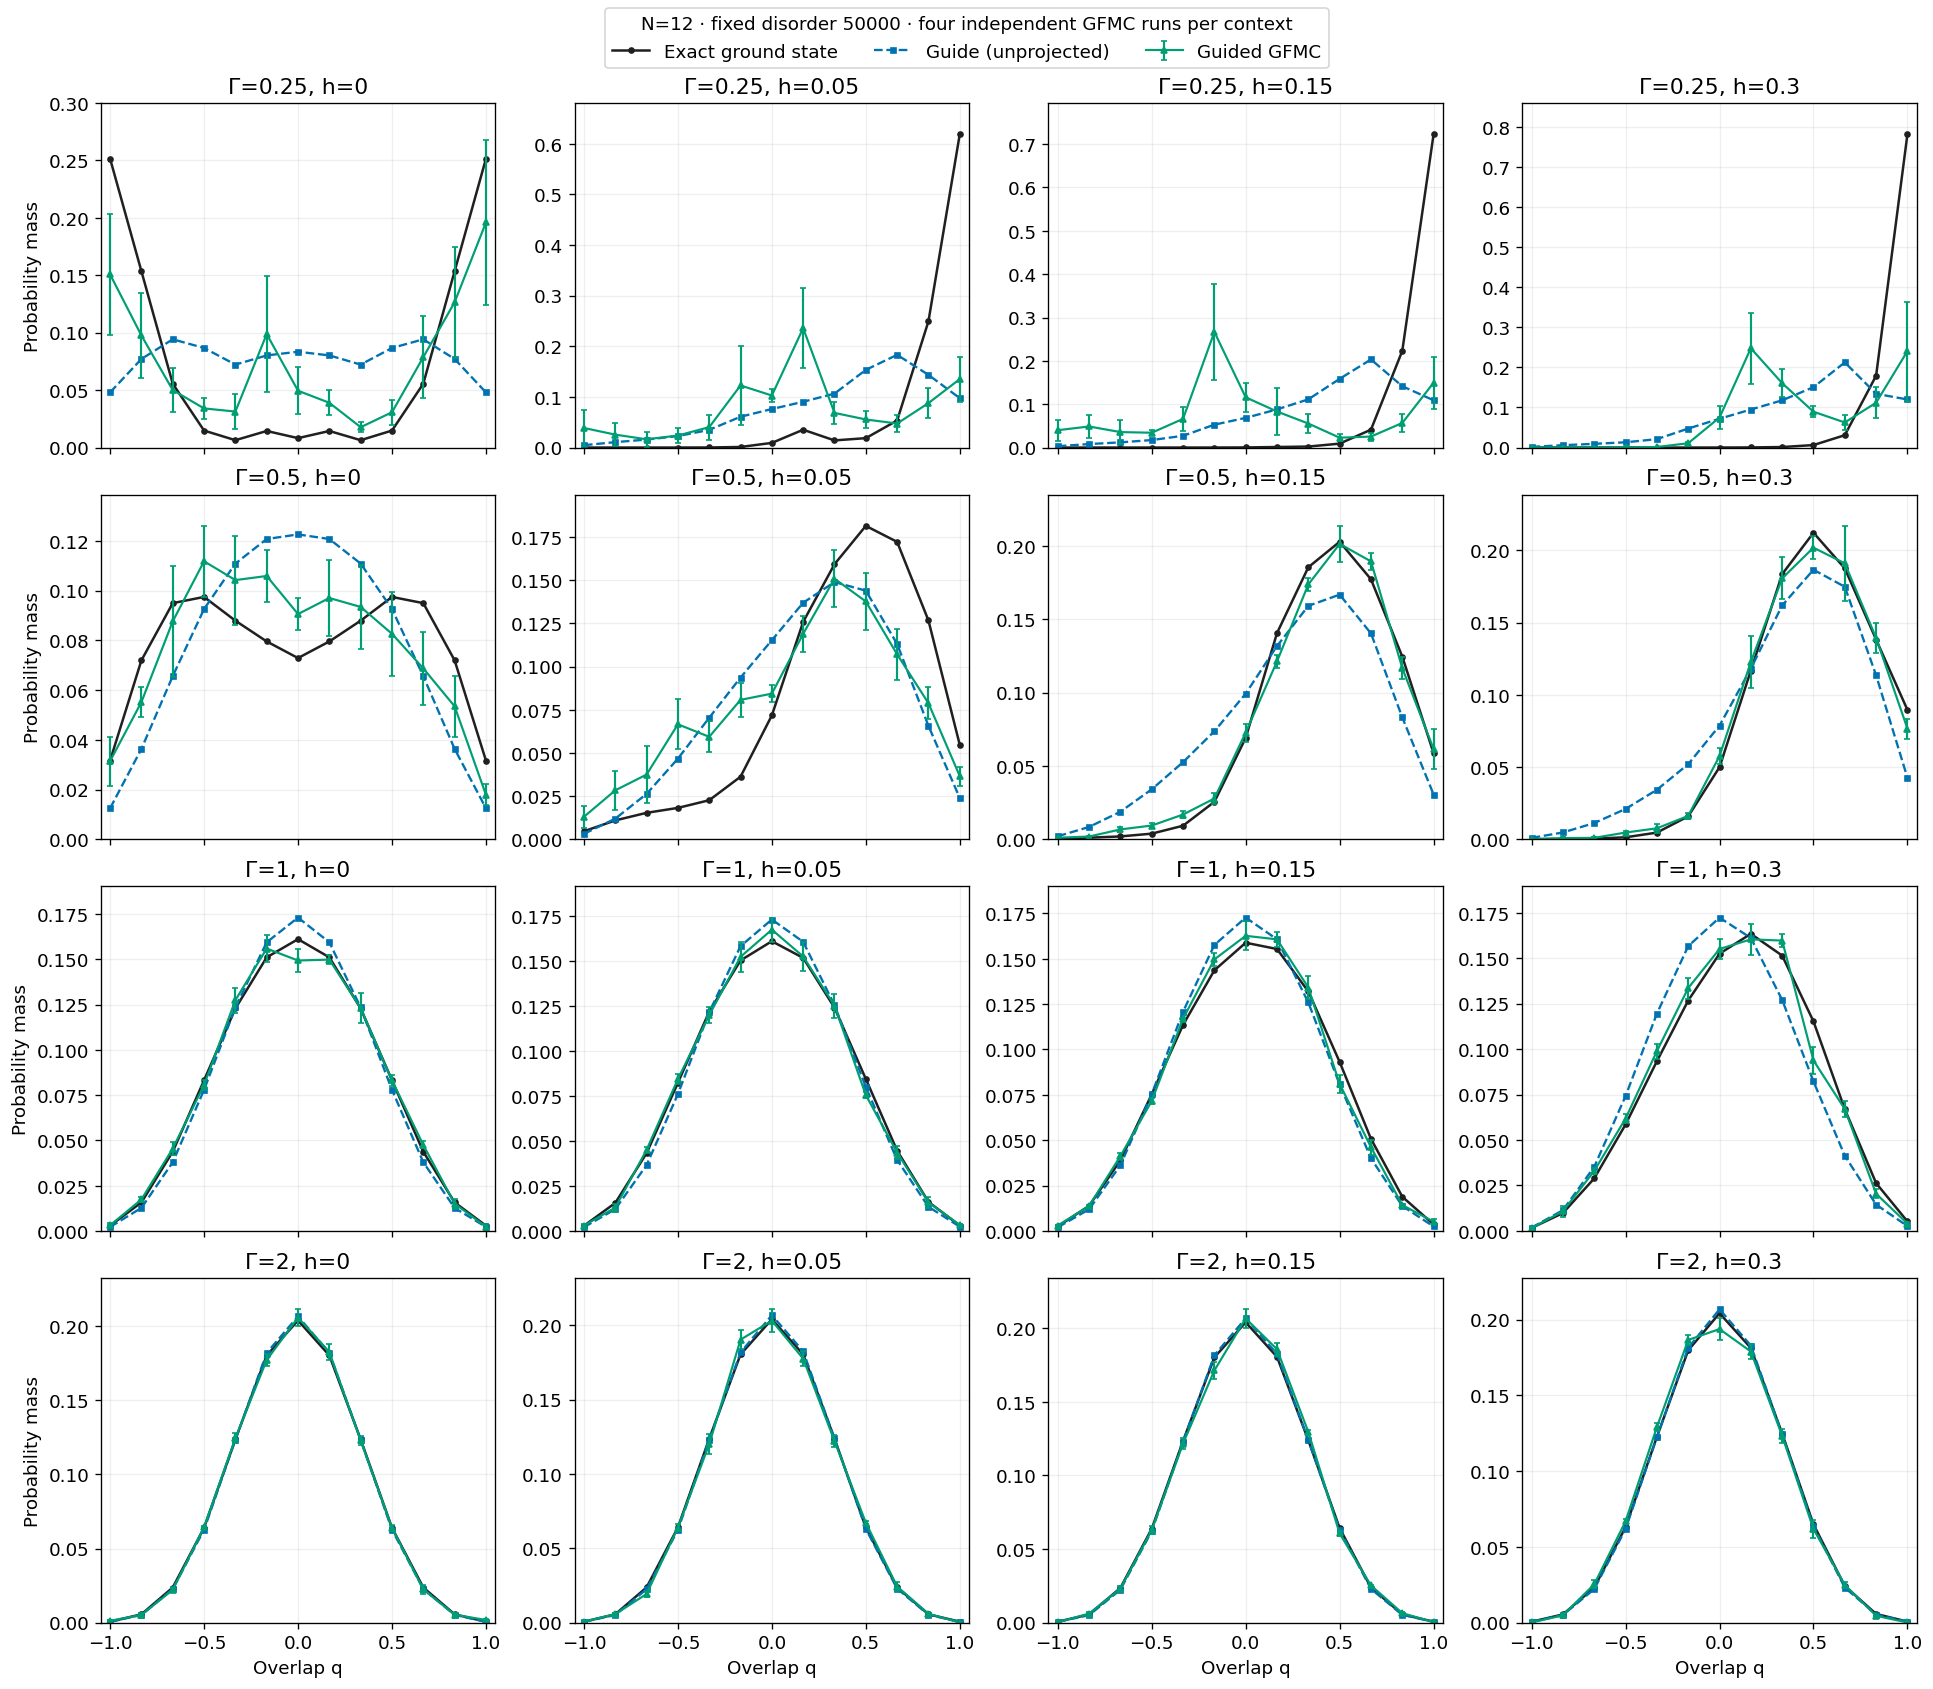

In [9]:
GRID = ROOT / 'data/kagome/guided_overlap_grid_v1'
compact_gammas = [.25, .5, 1., 2.]
compact_fields = [0., .05, .15, .30]
fig, axes = plt.subplots(4, 4, figsize=(16, 14), sharex=True,
                         layout='constrained')
for i, gamma in enumerate(compact_gammas):
    for j, h in enumerate(compact_fields):
        stem = f'L2_s50000_g{gamma:g}_h{h:g}_K1'.replace('.', 'p')
        ref = json.loads((GRID / (stem + '_reference.json')).read_text())
        runs = [json.loads((GRID / (stem + f'_repeat{r}.json')).read_text()) for r in range(4)]
        values = np.array([r['result']['pq'] for r in runs])
        mean, se = values.mean(0), values.std(0, ddof=1)/2
        bins = np.asarray(ref['q'])
        ax = axes[i, j]
        ax.plot(bins, ref['exact'], 'o-', color='#202020', markersize=3,
                linewidth=1.5, label='Exact ground state')
        ax.plot(bins, ref['guide'], 's--', color='#0072B2', markersize=3,
                linewidth=1.4, label='Guide (unprojected)')
        # ax.errorbar(bins, mean, yerr=se, fmt='^-', color='#009E73', markersize=4,
        #             capsize=2, linewidth=1.3, label='Guided GFMC ±1 run SE')
        ax.errorbar(bins, mean, yerr=se, fmt='^-', color='#009E73', markersize=4,
                   capsize=2, linewidth=1.3, label='Guided GFMC')
        ax.set(title=f'Γ={gamma:g}, h={h:g}', xlim=(-1.05, 1.05),
               xticks=[-1, -.5, 0, .5, 1])
        ax.grid(alpha=.2)
        if j == 0:
            ax.set_ylabel('Probability mass')
        if i == len(compact_gammas)-1:
            ax.set_xlabel('Overlap q')
        upper = max(max(ref['exact']), max(ref['guide']), max(mean + se))
        ax.set_ylim(0, .3 if (i, j) == (0, 0) else 1.1 * upper)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=3,
           title='N=12 · fixed disorder 50000 · four independent GFMC runs per context')
save_figure(fig, 'guided_gfmc_4x4')
plt.show()

## Full 7 × 7 field grid: exact, guide and guided GFMC

The available field grid contains seven transverse fields and seven longitudinal
fields, hence **49 panels**, not 81. Each panel below compares all four curves
on the same fixed disorder (ID 50000). This is an extension of the small-system
demonstration with four independent runs at each context, for **196 runs** total.
Its source, seeds, manifest and results are stored separately in
`data/kagome/guided_overlap_grid_v1`.

Settings are the same as the four-panel demonstration: 512 four-replica walkers,
equilibration time 4, energy measurement time 1, forward time 2, eight cycles, and
branch interval 0.1. This includes the difficult Gamma=0.25 cases without filtering
by accuracy or ancestry. Green error bars represent one Monte Carlo SE across four
whole-population runs. Each row shares a vertical scale; different rows may use
different scales. A panel annotation **A=n/4** counts runs triggering an ancestry
alarm. The figure does not establish convergence, particularly at low Gamma.

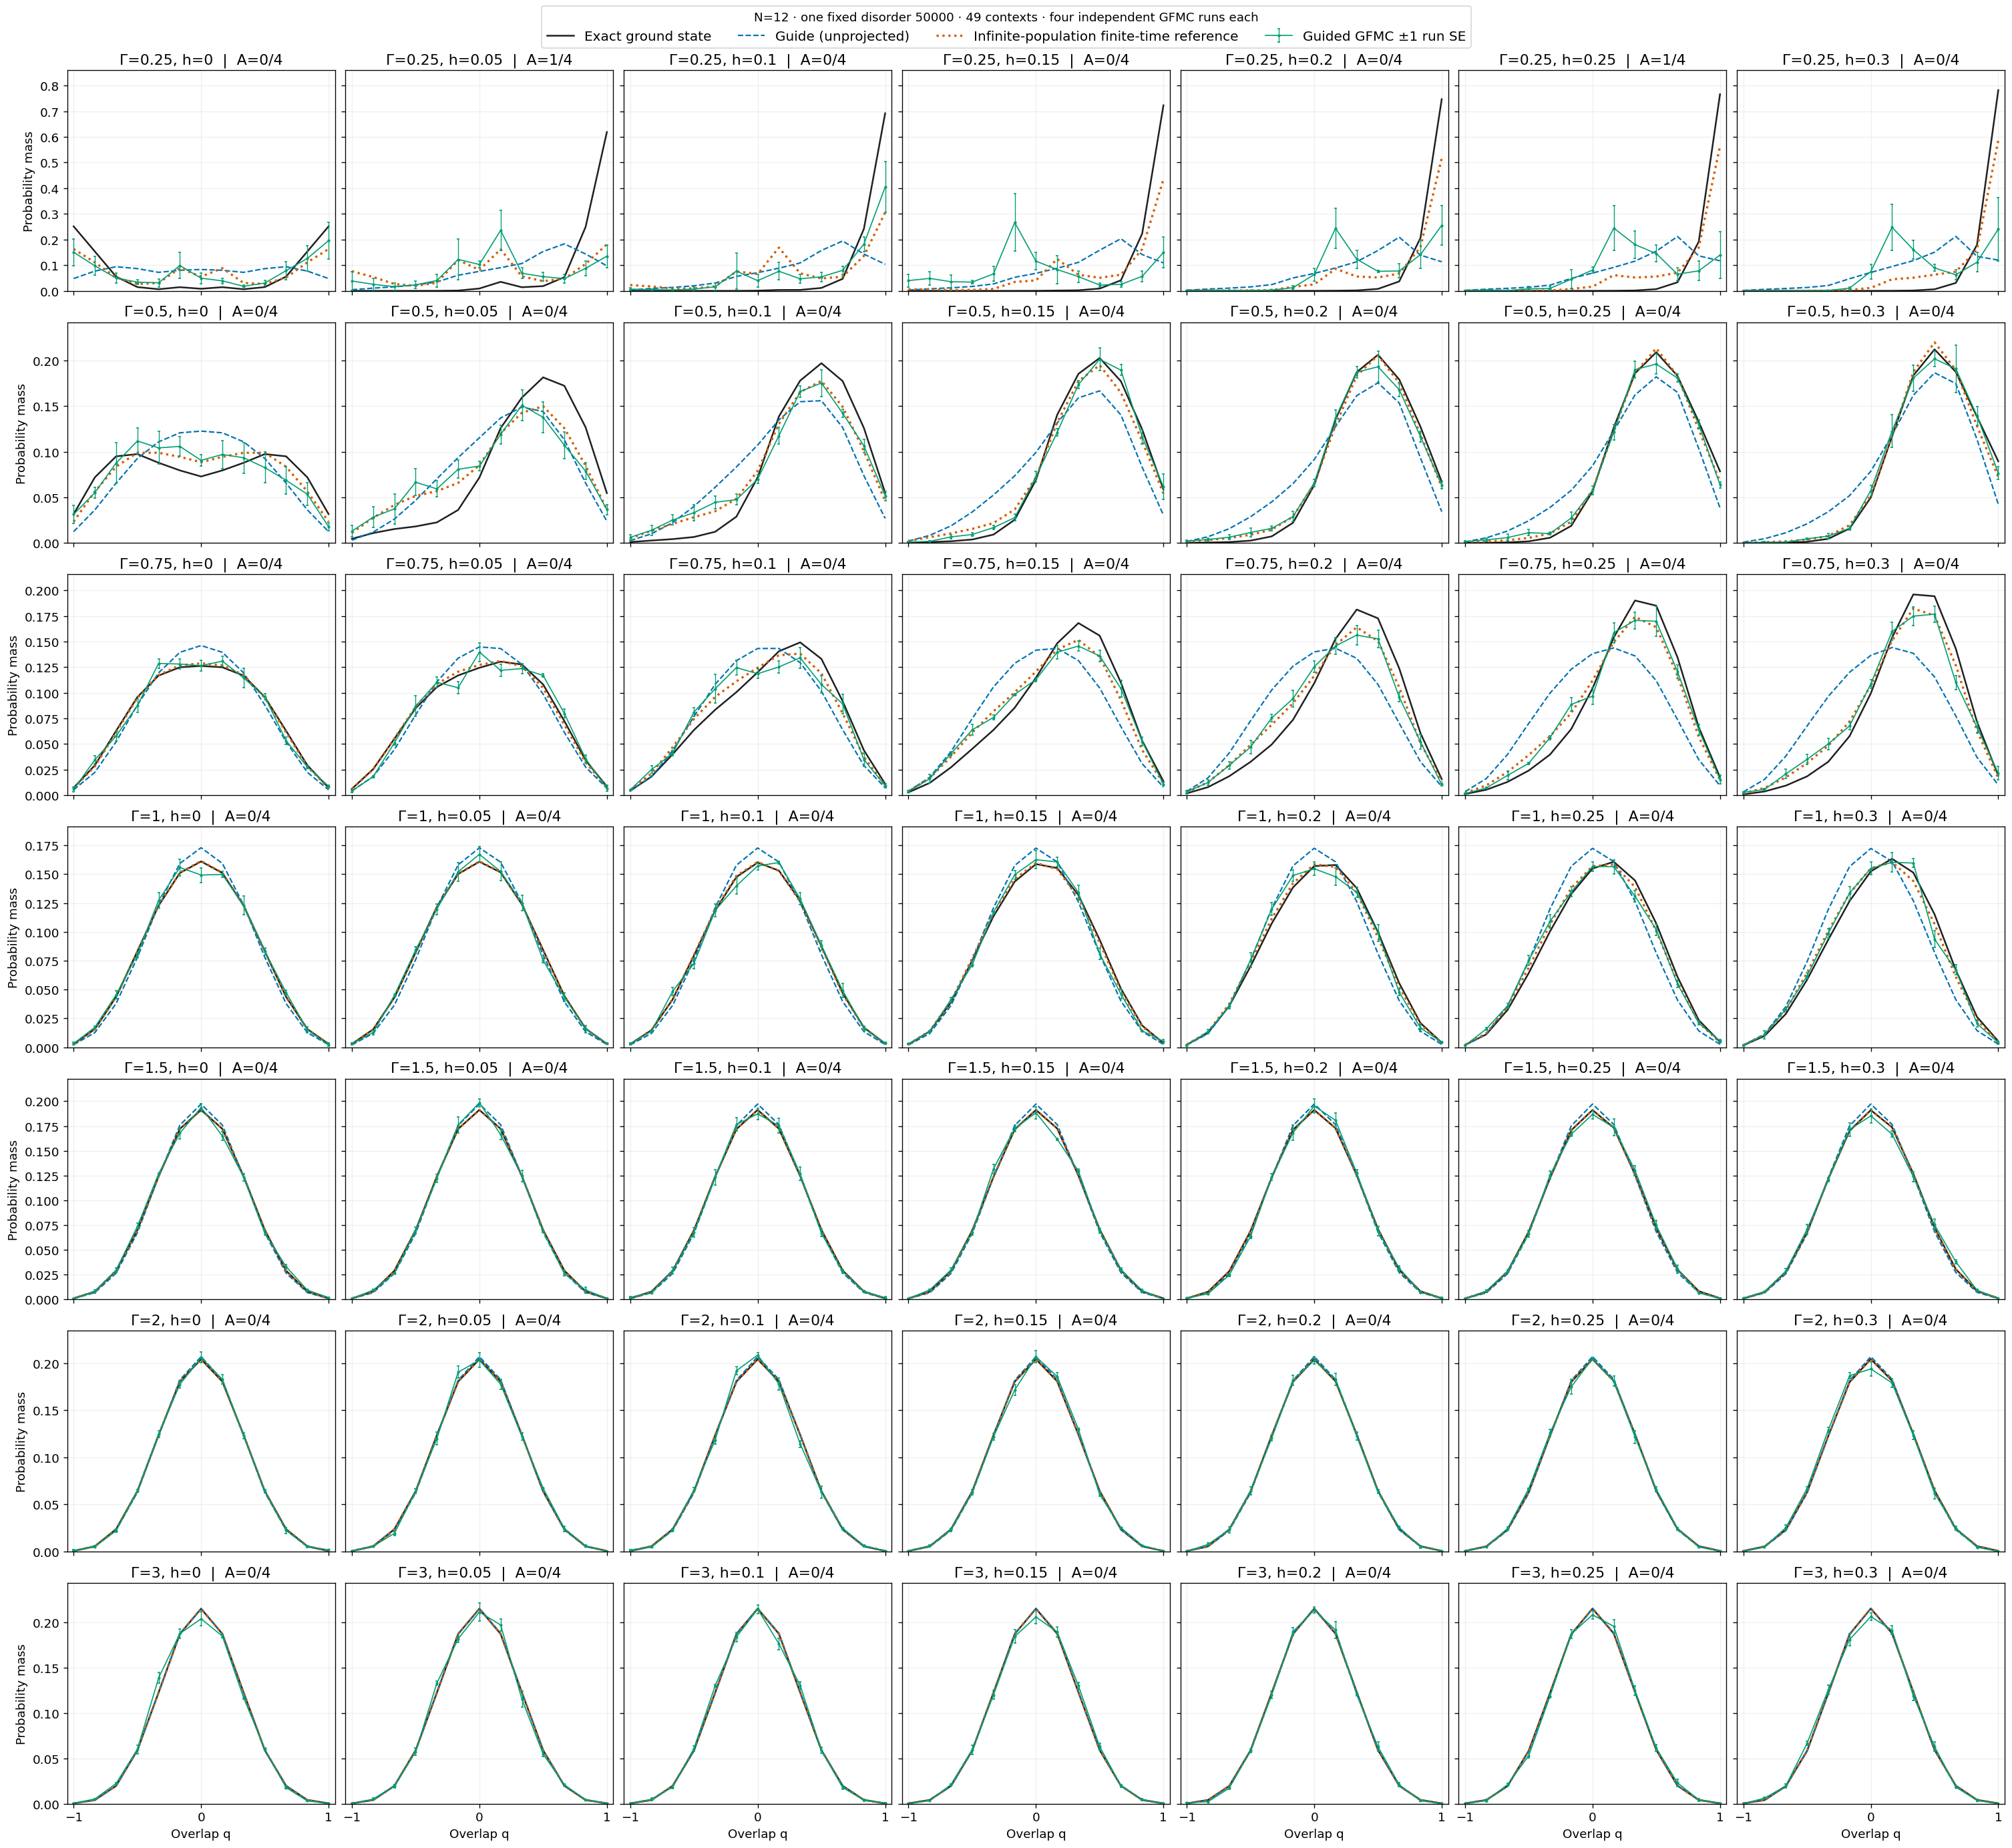

,gamma,h,guide_TV_to_ground,finite_time_TV_to_ground,GFMC_TV_to_ground,GFMC_TV_to_finite_time,minimum_ESS,maximum_lineage,ancestry_alarms,CPU_run_seconds
0,0.25,0.00,0.55933,0.26872,0.24466,0.09632,11.37975,0.28516,0,1.21945
1,0.25,0.05,0.62725,0.58813,0.65135,0.14012,7.57291,0.34961,1,1.26541
2,0.25,0.10,0.68648,0.49211,0.34678,0.17774,8.80801,0.32031,0,1.22552
3,0.25,0.15,0.69548,0.34884,0.75555,0.50538,8.58869,0.32812,0,1.21456
4,0.25,0.20,0.70059,0.26551,0.55650,0.29779,12.87418,0.26172,0,1.21836
5,0.25,0.25,0.70437,0.22576,0.74031,0.52073,4.15640,0.48633,1,1.23789
6,0.25,0.30,0.70723,0.21291,0.60878,0.40887,14.57651,0.24023,0,1.25442
7,0.50,0.00,0.17810,0.07029,0.09771,0.04648,61.07735,0.08008,0,2.06810
8,0.50,0.05,0.20036,0.16032,0.19024,0.04317,24.86191,0.17773,0,2.07477
9,0.50,0.10,0.19912,0.10272,0.11491,0.03263,42.81999,0.11328,0,2.24122


Validated 196 runs × 8 cycles with independent seeds and histogram/scalar moment agreement.
Total local CPU propagation wall time: 245.61 seconds
Runs with ancestry alarms: 2 / 196


1205

In [7]:
GRID = ROOT / 'data/kagome/guided_overlap_grid_v1'
grid_manifest = json.loads((GRID / 'manifest.json').read_text())
assert len(grid_manifest['contexts']) == 49 and grid_manifest['repeats'] == 4
for relative, digest in grid_manifest['source_sha256'].items():
    assert hashlib.sha256((GRID / 'source' / relative).read_bytes()).hexdigest() == digest
grid_gammas = sorted({c[0] for c in grid_manifest['contexts']})
grid_fields = sorted({c[1] for c in grid_manifest['contexts']})
fig, axes = plt.subplots(7, 7, figsize=(25, 23), sharex=True, sharey='row',
                         layout='constrained')
grid_rows, grid_bins, all_seeds = [], [], []
for i, gamma in enumerate(grid_gammas):
    upper = 0.
    for j, h in enumerate(grid_fields):
        ax = axes[i, j]
        stem = f'L2_s50000_g{gamma:g}_h{h:g}_K1'.replace('.', 'p')
        ref = json.loads((GRID / (stem + '_reference.json')).read_text())
        for relative, digest in ref['input_sha256'].items():
            assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == digest
        runs = [json.loads((GRID / (stem + f'_repeat{r}.json')).read_text()) for r in range(4)]
        bins = np.asarray(ref['q'])
        for run in runs:
            assert run['parameters'] == grid_manifest['parameters']
            assert run['input_sha256'] == ref['input_sha256']
            assert run['sample_id'] == grid_manifest['sample_id']
            hist = np.asarray(run['result']['pq_cycles'])
            np.testing.assert_allclose(hist.sum(1), 1, atol=1e-12)
            np.testing.assert_allclose(hist.mean(0), run['result']['pq'], atol=1e-12)
            for power, name in [(1, 'q'), (2, 'q2'), (4, 'q4')]:
                np.testing.assert_allclose(hist @ bins**power, run['result'][name + '_cycles'], atol=1e-12)
            all_seeds.append(run['seed'])
        values = np.array([r['result']['pq'] for r in runs])
        mean, se = values.mean(0), values.std(0, ddof=1)/2
        alarms = sum(r['ancestry_alarm'] for r in runs)
        ax.plot(bins, ref['exact'], color='#202020', linewidth=1.5, label='Exact ground state')
        ax.plot(bins, ref['guide'], '--', color='#0072B2', linewidth=1.3, label='Guide (unprojected)')
        ax.plot(bins, ref['finite_time'], ':', color='#D55E00', linewidth=2,
                label='Infinite-population finite-time reference')
        ax.errorbar(bins, mean, yerr=se, fmt='.-', color='#009E73', markersize=3,
                    linewidth=1, elinewidth=.8, capsize=1, label='Guided GFMC ±1 run SE')
        ax.set(title=f'Γ={gamma:g}, h={h:g}  |  A={alarms}/4',
               xlim=(-1.05, 1.05), xticks=[-1, 0, 1])
        ax.grid(alpha=.18)
        if j == 0:
            ax.set_ylabel('Probability mass')
        if i == 6:
            ax.set_xlabel('Overlap q')
        upper = max(upper, max(ref['exact']), max(ref['guide']), max(ref['finite_time']), max(mean+se))
        grid_rows.append(dict(gamma=gamma, h=h,
            guide_TV_to_ground=.5*np.abs(np.asarray(ref['guide'])-ref['exact']).sum(),
            finite_time_TV_to_ground=.5*np.abs(np.asarray(ref['finite_time'])-ref['exact']).sum(),
            GFMC_TV_to_ground=.5*np.abs(mean-ref['exact']).sum(),
            GFMC_TV_to_finite_time=.5*np.abs(mean-ref['finite_time']).sum(),
            minimum_ESS=min(min(r['result']['descendant_ess']) for r in runs),
            maximum_lineage=max(max(r['result']['largest_lineage']) for r in runs),
            ancestry_alarms=alarms, CPU_run_seconds=sum(r['seconds'] for r in runs)))
        for k, value in enumerate(bins):
            grid_bins.append(dict(gamma=gamma, h=h, q=value, exact=ref['exact'][k],
                guide=ref['guide'][k], finite_time=ref['finite_time'][k], GFMC_mean=mean[k], GFMC_se=se[k]))
    axes[i, 0].set_ylim(0, 1.1*upper)
assert len(all_seeds) == len(set(all_seeds)) == 196
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=4, fontsize=12,
           title='N=12 · one fixed disorder 50000 · 49 contexts · four independent GFMC runs each')
save_figure(fig, 'guided_gfmc_full_grid')
plt.show()
grid_diagnostics = pd.DataFrame(grid_rows)
grid_diagnostics.to_csv(OUT / 'guided_gfmc_grid_diagnostics.csv', index=False)
pd.DataFrame(grid_bins).to_csv(OUT / 'guided_gfmc_grid_histograms.csv', index=False)
display(grid_diagnostics.round(5))
print('Validated 196 runs × 8 cycles with independent seeds and histogram/scalar moment agreement.')
print('Total local CPU propagation wall time:', round(grid_diagnostics.CPU_run_seconds.sum(), 2), 'seconds')
print('Runs with ancestry alarms:', int(grid_diagnostics.ancestry_alarms.sum()), '/ 196')
note = f"""# Guided-GFMC overlap grid

N=12, L=2 kagome PBC, fixed disorder 50000. The 49 contexts use four independent
runs each: W=512 four-replica walkers, equilibration time 4, energy measurement time 1,
forward time 2, eight cycles and branch interval 0.1. All run and cycle histograms
are retained. Histogram normalization and first, second and fourth moments were
validated against scalar tags in all 1,568 cycles.

The comparison uses exact ground-state probabilities, the frozen unprojected guide,
guided GFMC with one-run-mean standard errors, and a deterministic infinite-population
reference at the same finite projection times. The same disorder is used for every
curve. There is no disorder averaging in this figure. No convergence claim is made.

{int(grid_diagnostics.ancestry_alarms.sum())}/196 runs triggered an ancestry alarm.
Local lookup-GFMC propagation took {grid_diagnostics.CPU_run_seconds.sum():.2f} seconds,
excluding deterministic references and plotting; this is not a direct-network GPU cost.

Figure: guided_gfmc_full_grid.png / guided_gfmc_full_grid.pdf.
Tables: guided_gfmc_grid_histograms.csv / guided_gfmc_grid_diagnostics.csv.
Notebook: ../../notebook/exact_guide_overlap_distributions.ipynb.
Frozen inputs and source: ../../data/kagome/guided_overlap_grid_v1/.
"""
(OUT / 'GUIDED_GFMC_GRID.md').write_text(note)